In [104]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
zynicide_wine_reviews_path = kagglehub.dataset_download('zynicide/wine-reviews')

print('Data source import complete.')


Using Colab cache for faster access to the 'wine-reviews' dataset.
Data source import complete.


In [105]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")


VERİYİ OKUMA VE TEMEL TEMİZLİK

In [106]:
df = pd.read_csv("winemag-data-130k-v2.csv")
df.head(3)

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm


In [107]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129971 entries, 0 to 129970
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Unnamed: 0             129971 non-null  int64  
 1   country                129908 non-null  object 
 2   description            129971 non-null  object 
 3   designation            92506 non-null   object 
 4   points                 129971 non-null  int64  
 5   price                  120975 non-null  float64
 6   province               129908 non-null  object 
 7   region_1               108724 non-null  object 
 8   region_2               50511 non-null   object 
 9   taster_name            103727 non-null  object 
 10  taster_twitter_handle  98758 non-null   object 
 11  title                  129971 non-null  object 
 12  variety                129970 non-null  object 
 13  winery                 129971 non-null  object 
dtypes: float64(1), int64(2), object(11)


In [108]:
df = df.drop(columns="Unnamed: 0", axis=1)

In [109]:
df.describe()

,points,price
count,129971.000000,120975.000000
mean,88.447138,35.363389
std,3.039730,41.022218
min,80.000000,4.000000
25%,86.000000,17.000000
50%,88.000000,25.000000
75%,91.000000,42.000000
max,100.000000,3300.000000


In [110]:
df[df.duplicated(subset = ["description"])]

,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
2408,US,"This is weighty, creamy and medium to full in ...",NaN,85,14.0,California,North Coast,North Coast,Virginie Boone,@vboone,Souverain 2010 Chardonnay (North Coast),Chardonnay,Souverain
2409,Italy,There's a touch of toasted almond at the start...,Sallier de la Tour,85,13.0,Sicily & Sardinia,Sicilia,NaN,NaN,NaN,Tasca d'Almerita 2011 Sallier de la Tour Grill...,Grillo,Tasca d'Almerita
2410,Chile,Lightly herbal strawberry and raspberry aromas...,Reserve,85,13.0,Maipo Valley,NaN,NaN,Michael Schachner,@wineschach,Tres Palacios 2011 Reserve Pinot Noir (Maipo V...,Pinot Noir,Tres Palacios
2412,Italy,The Monica grape often shows a rustic or raw q...,Dolia,85,14.0,Sicily & Sardinia,Monica di Sardegna,NaN,NaN,NaN,Cantine di Dolianova 2010 Dolia (Monica di Sa...,Monica,Cantine di Dolianova
2413,France,"Fruity and lightly herbaceous, this has fine t...",La Fleur d'Amélie,85,15.0,Bordeaux,Bordeaux Blanc,NaN,Roger Voss,@vossroger,Château de Sours 2011 La Fleur d'Amélie (Bord...,Bordeaux-style White Blend,Château de Sours
...,...,...,...,...,...,...,...,...,...,...,...,...,...
129879,US,"This wine is a blend of 45% Grenache, 37% Syra...",Metis,90,20.0,Washington,Columbia Valley (WA),Columbia Valley,Sean P. Sullivan,@wawinereport,Maison Bleue 2013 Metis Red (Columbia Valley (...,Red Blend,Maison Bleue
129880,US,Apple blossom intrigues on the nose of this li...,NaN,90,20.0,California,Russian River Valley,Sonoma,Virginie Boone,@vboone,Martin Ray 2015 Chardonnay (Russian River Valley),Chardonnay,Martin Ray
129881,Spain,This Verdejo smells like citrus fruits and wil...,NaN,90,19.0,Northern Spain,Rueda,NaN,Michael Schachner,@wineschach,Martinsancho 2015 Verdejo (Rueda),Verdejo,Martinsancho
129882,US,"This wine is mostly Cabernet Sauvignon (78%), ...",Reserve,90,60.0,Washington,Columbia Valley (WA),Columbia Valley,Sean P. Sullivan,@wawinereport,Matthews 2012 Reserve Red (Columbia Valley (WA)),Bordeaux-style Red Blend,Matthews


In [111]:
df = df.drop_duplicates(subset=["description"]).reset_index(drop=True)
df_clean = df.dropna(subset=['price', 'points', 'country', 'variety']).copy()


In [112]:
print(f"Temizlik sonrası boyut: {df_clean.shape}")

Temizlik sonrası boyut: (111511, 13)


In [113]:
for col in df_clean.columns:
    print("-------------------------------")
    print(df_clean[col].value_counts())


-------------------------------
country
US                        50229
France                    16286
Italy                     15492
Spain                      6049
Portugal                   4502
Chile                      4129
Argentina                  3500
Austria                    2535
Australia                  2169
Germany                    1951
New Zealand                1240
South Africa               1195
Israel                      453
Greece                      426
Canada                      224
Bulgaria                    132
Hungary                     128
Romania                     102
Uruguay                      98
Turkey                       81
Georgia                      74
Slovenia                     70
Croatia                      68
Mexico                       68
England                      59
Moldova                      56
Brazil                       44
Lebanon                      32
Morocco                      24
Peru                         16


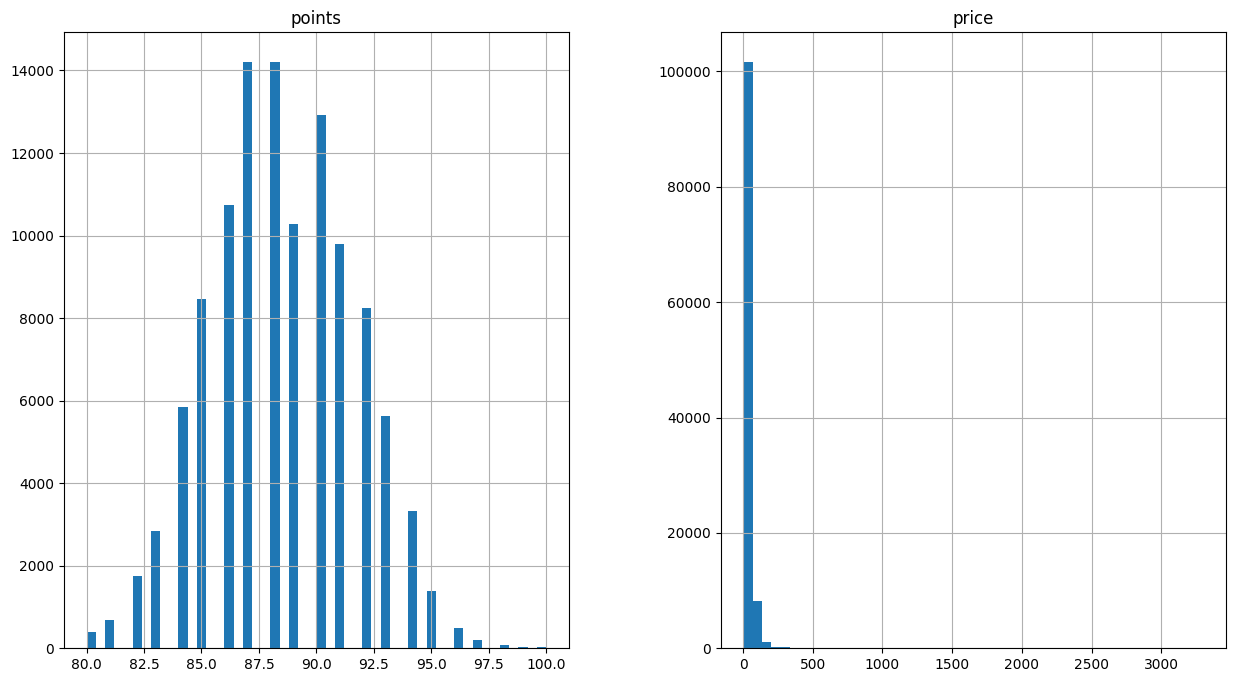

In [114]:
#sayısal değişkenleirn dağılımı
df_clean.hist(bins=50,figsize=(15,8))
plt.show()

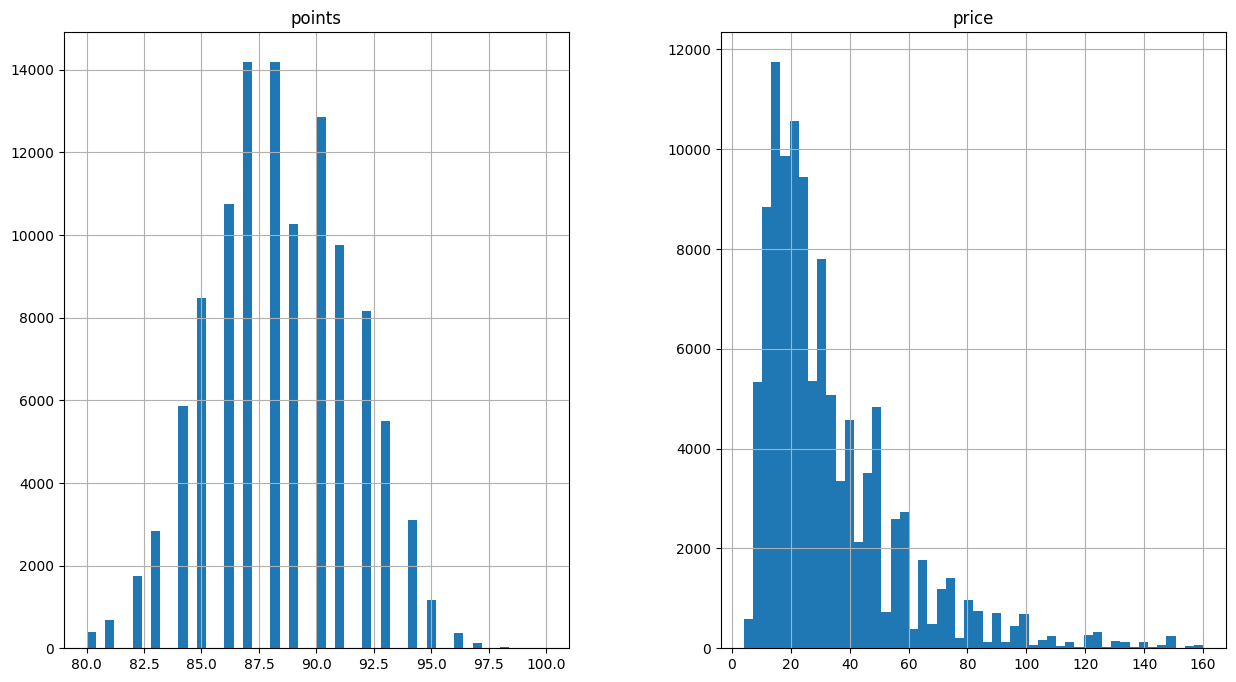

In [115]:
#fiyattaki en uç %1'lik aşırı değerleri kırpma
price_cap = df_clean["price"].quantile(0.99)
df_clean = df_clean[df_clean["price"]<=price_cap].reset_index(drop=True)

#kırpılmış halinin grafği
df_clean.hist(bins=50,figsize=(15,8))
plt.show()

<Axes: >

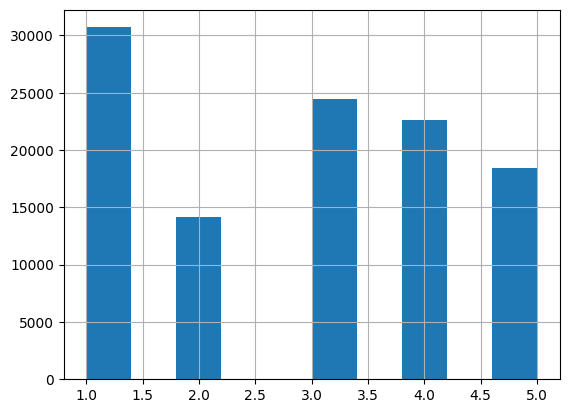

In [116]:
#tabakalı örnekleme için puanı 5 eşit dilime ayırma
df_clean['points_cat'] = pd.qcut(df_clean['points'], q=5, labels=[1, 2, 3, 4, 5])
df_clean["points_cat"].hist()

In [117]:
from sklearn.model_selection import StratifiedShuffleSplit
split_sample = StratifiedShuffleSplit(n_splits=1, train_size=4000, random_state=42)
for sample_index,_ in split_sample.split(df_clean,df_clean["points_cat"]):
    df_llm_sample = df_clean.loc[sample_index].reset_index(drop=True)

print("Ana Veri Oranları:\n", df_clean["points_cat"].value_counts()/len(df_clean))

print("\n4000'lük Örneklem Oranları:\n", df_llm_sample["points_cat"].value_counts()/4000)



Ana Veri Oranları:
 points_cat
1    0.278065
3    0.221342
4    0.204798
5    0.167263
2    0.128533
Name: count, dtype: float64

4000'lük Örneklem Oranları:
 points_cat
1    0.27800
3    0.22150
4    0.20475
5    0.16725
2    0.12850
Name: count, dtype: float64


LLM

In [118]:
from tqdm import tqdm
from pydantic import BaseModel
from google import genai
from google.genai import types
from google.colab import userdata

csv_dosya_adi = "sarap_llm_4000.csv"

if os.path.exists(csv_dosya_adi):
    print("CSV dosyası zaten mevcut, veriler doğrudan dosyadan okunuyor...")
    df_final = pd.read_csv(csv_dosya_adi)

else:
    api_key = userdata.get('Gemini_API_Key')
    client = genai.Client(api_key=api_key)

    class WineFeatures(BaseModel):
        sentiment: float
        body: float
        acidity: float
        complexity: float
        aging: float

    #API hatası olursa atanacak ortalama değerler
    varsayilan_skorlar = {
        'sentiment': 6.0,
        'body': 6.0,
        'acidity': 6.0,
        'complexity': 6.0,
        'aging': 6.0
    }

    def analyze_wine_note(note_text):
        prompt = f"""
        Sen uzman bir sommeliersin. Verilen tadım notunu dikkatle analiz et.
        Her bir metriği 1.0 (en zayıf/en düşük) ile 10.0 (en güçlü/en yüksek) arasında hassas ondalıklı puanla:
        - sentiment: Metindeki genel övgü, beğeni ve kalite düzeyi.
        - body: Şarabın gövdesi, ağırlığı ve tanen yoğunluğu.
        - acidity: Şarabın asiditesi, ferahlığı ve canlılığı.
        - complexity: Meşe, meyve, baharat ve aroma katmanlarının zenginliği.
        - aging: Şarabın yıllanmaya ve mahzende bekletilmeye uygunluğu.

        Tadım Notu: "{note_text}"
        """

        response = client.models.generate_content(
            model='gemini-3.1-flash-lite',
            contents=prompt,
            config=types.GenerateContentConfig(
                response_mime_type="application/json",
                response_schema=WineFeatures,
                temperature=0.0
            )
        )
        return response.parsed.model_dump()

    sonuclar = []
    print("Tadım notları Gemini ile analiz ediliyor...")

    for i, note in enumerate(tqdm(df_llm_sample['description'])):
        try:
            skor = analyze_wine_note(note)
            time.sleep(0.02)
        except Exception as e:
            print(f"{i}. satırda hata oluştu, varsayılan skor atandı:", e)
            skor = varsayilan_skorlar.copy()
            time.sleep(1)

        sonuclar.append(skor)

    df_llm_features = pd.DataFrame(sonuclar)
    df_final = pd.concat([df_llm_sample.reset_index(drop=True), df_llm_features], axis=1)

    df_final.to_csv(csv_dosya_adi, index=False)
    print("Analiz bitti ve dosyaya kaydedildi.")

df_final[['description', 'sentiment', 'body', 'acidity', 'complexity', 'aging', 'points']].head(3)


CSV dosyası zaten mevcut, veriler doğrudan dosyadan okunuyor...


,description,sentiment,body,acidity,complexity,aging,points
0,This fresh Sauvignon does a great job of contr...,8.5,6.5,8.0,7.0,4.0,87
1,"As always, Loios is a bright and fruity wine t...",7.5,4.2,7.8,4.5,3.0,85
2,This is a distinctive dessert wine that opens ...,7.5,9.2,4.5,8.0,8.5,86


VERİ KEŞFİ

In [119]:
df_final['points_cat'] = pd.qcut(df_final['points'], q=5, labels=[1, 2, 3, 4, 5])

split = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
for train_index, test_index in split.split(df_final, df_final['points_cat']):
    strat_train_set = df_final.loc[train_index].reset_index(drop=True)
    strat_test_set = df_final.loc[test_index].reset_index(drop=True)


In [120]:
#geçici tabaka sütununu kaldırıyoruz
for s in (strat_train_set, strat_test_set):
    s.drop(columns=['points_cat'], inplace=True)

print(f"\nEğitim Seti: {len(strat_train_set)} | Test Seti: {len(strat_test_set)}")


Eğitim Seti: 3200 | Test Seti: 800


In [121]:
#test setine bakmadan isttikiği veri okuma
train_vintages = strat_train_set['title'].str.extract(r"\b(19\d\d|20[0-2]\d)\b")[0].astype(float)
vintage_median = train_vintages.median()

top_countries = strat_train_set['country'].value_counts().nlargest(8).index.tolist()
top_varieties = strat_train_set['variety'].value_counts().nlargest(8).index.tolist()

for s in (strat_train_set, strat_test_set):
    s['log_price'] = np.log1p(s['price'])
    s['word_count'] = s['description'].str.split().str.len()

    s['vintage'] = s['title'].str.extract(r"\b(19\d\d|20[0-2]\d)\b")[0].astype(float)
    s['vintage'] = s['vintage'].fillna(vintage_median)
    s['wine_age'] = (2017 - s['vintage']).clip(lower=0, upper=40)

    s['country_grp'] = s['country'].where(s['country'].isin(top_countries), 'Other')
    s['variety_grp'] = s['variety'].where(s['variety'].isin(top_varieties), 'Other')


In [122]:
df_wine = strat_train_set.copy()

num_cols = ['points', 'log_price', 'word_count', 'wine_age',
            'sentiment', 'body', 'acidity', 'complexity', 'aging']

display(df_wine[num_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
points,3200.0,88.35,3.03,80.00,86.00,88.00,91.00,97.00
log_price,3200.0,3.33,0.60,1.95,2.89,3.26,3.71,5.08
word_count,3200.0,40.59,11.28,10.00,33.00,40.00,47.00,98.00
wine_age,3200.0,6.27,3.48,1.00,4.00,6.00,8.00,25.00
sentiment,3200.0,7.39,1.71,1.20,6.50,7.50,8.50,9.80
body,3200.0,6.51,1.80,2.00,5.20,6.50,8.20,9.80
acidity,3200.0,7.03,1.34,2.00,6.50,7.20,7.80,9.80
complexity,3200.0,6.62,1.63,1.50,5.50,7.00,7.80,9.80
aging,3200.0,5.17,2.29,1.00,3.00,5.00,7.00,9.80


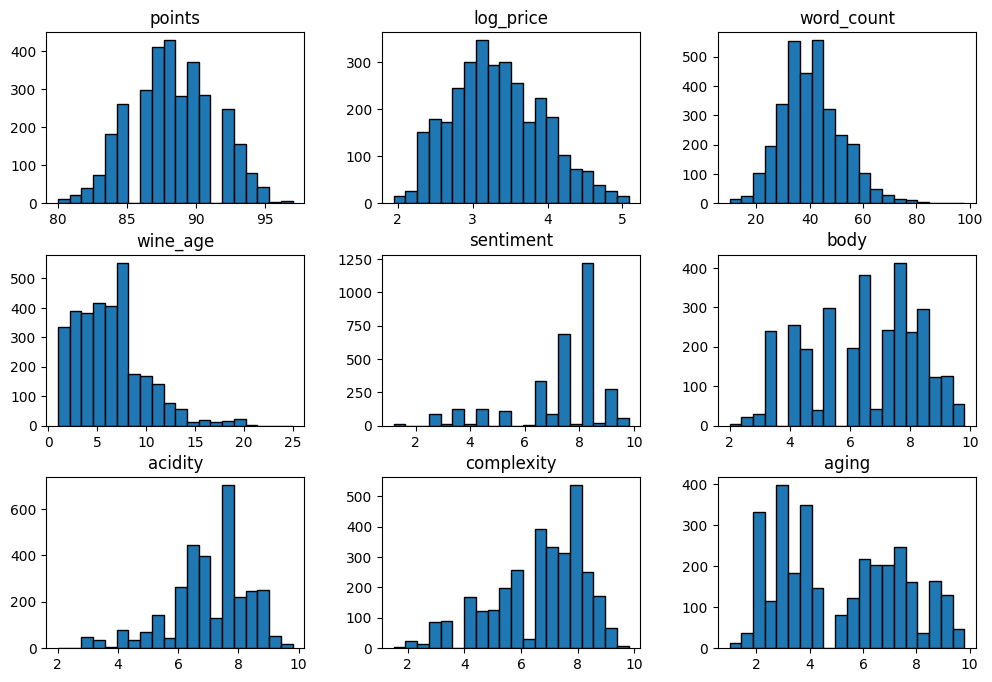

In [123]:
import matplotlib.pyplot as plt



df_wine[num_cols].hist(bins=20, figsize=(12, 8), edgecolor='black', grid=False)
plt.show()

<Axes: >

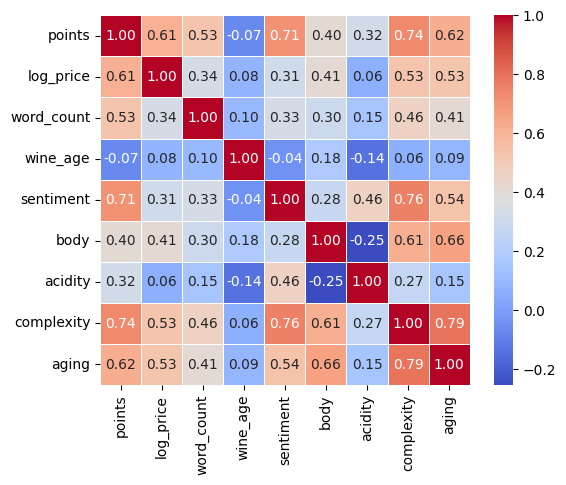

In [124]:
corr_matrix = df_wine[num_cols].corr()
#Korelasyon Isı Haritası
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    square=True
)


In [125]:
corr_matrix["points"].sort_values(ascending=False).round(3)

,points
points,1.000
complexity,0.735
sentiment,0.708
aging,0.620
log_price,0.611
word_count,0.532
body,0.404
acidity,0.321
wine_age,-0.071


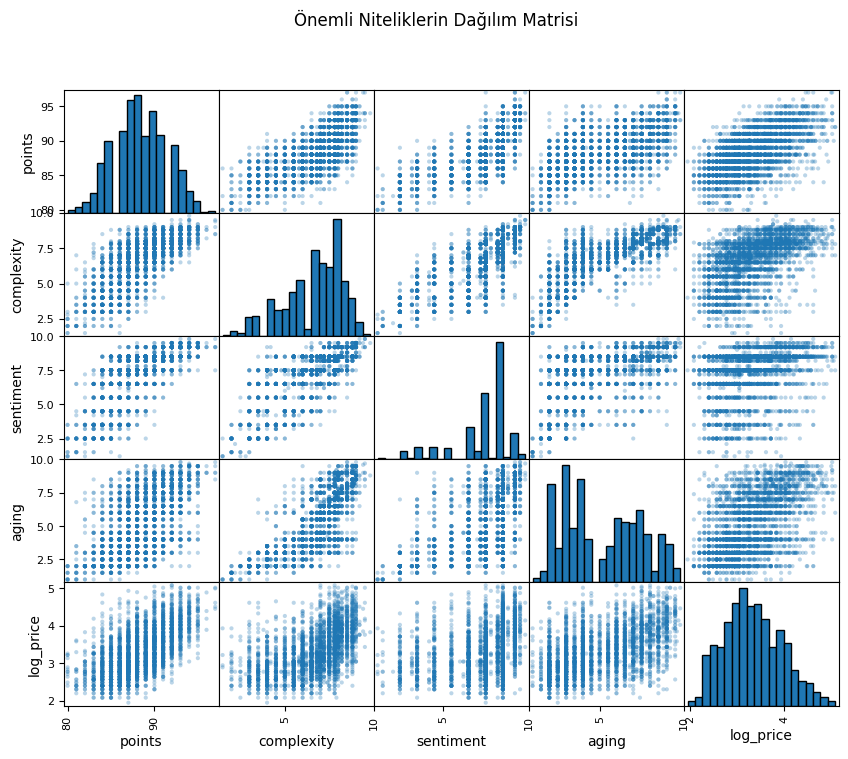

In [126]:
from pandas.plotting import scatter_matrix

onemli_nitelikler = ["points", "complexity", "sentiment", "aging", "log_price"]

scatter_matrix(
    df_wine[onemli_nitelikler],
    figsize=(10, 8),
    alpha=0.3,
    hist_kwds={'bins': 20, 'edgecolor': 'black'}
)
plt.suptitle("Önemli Niteliklerin Dağılım Matrisi ")
plt.show()


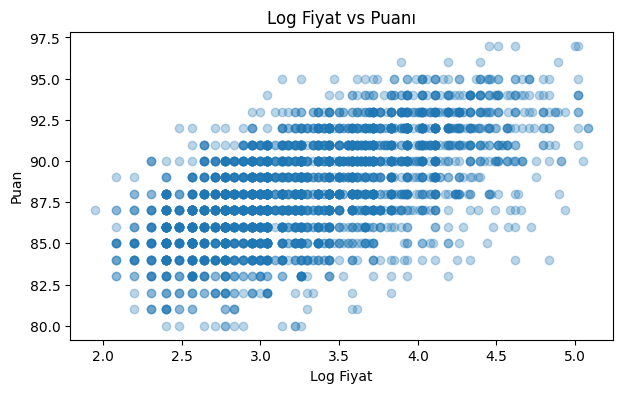

In [127]:

plt.figure(figsize=(7, 4))
plt.scatter(df_wine["log_price"], df_wine["points"], alpha=0.3)
plt.title("Log Fiyat vs Puanı")
plt.xlabel("Log Fiyat")
plt.ylabel("Puan")
plt.show()


In [128]:
df_wine.groupby('country_grp')['points'].agg(
    ortalama_puan='mean',
    medyan_puan='median',
    sarap_sayisi='count'
).sort_values(by='ortalama_puan', ascending=False)


,ortalama_puan,medyan_puan,sarap_sayisi
country_grp,,,
Austria,90.435294,90.0,85
Other,88.619565,89.0,276
Italy,88.611765,88.0,425
Portugal,88.603306,88.0,121
France,88.490196,88.0,510
US,88.474138,88.0,1392
Spain,86.844720,87.0,161
Chile,86.664430,86.0,149
Argentina,86.641975,87.0,81


In [129]:
llm_cols = ['sentiment', 'body', 'acidity', 'complexity', 'aging']

grup_kiyas = df_wine.groupby(df_wine['points'] >= 90)[llm_cols].mean().round(2)
grup_kiyas.index = ['90 puan altı şaraplar', '90 üstü şaraplar']

grup_kiyas.T


,90 puan altı şaraplar,90 üstü şaraplar
sentiment,6.73,8.51
body,6.02,7.33
acidity,6.83,7.37
complexity,5.89,7.84
aging,4.26,6.70


<Axes: xlabel='price', ylabel='points'>

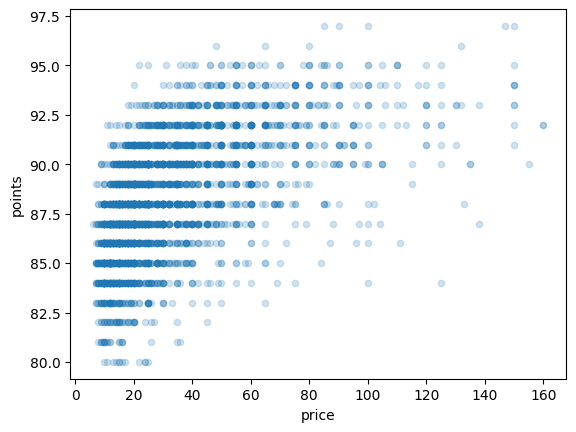

In [130]:
df_wine.plot(kind="scatter", x="price", y="points", alpha=0.2)

<Axes: xlabel='log_price', ylabel='points'>

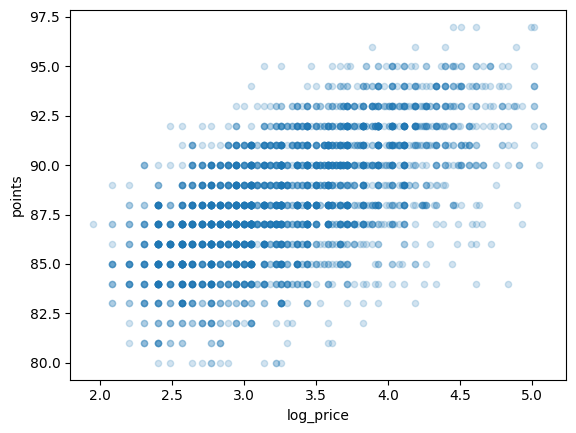

In [131]:
df_wine.plot(kind="scatter", x="log_price", y="points", alpha=0.2)

In [132]:
corr_matrix = df_wine.corr(numeric_only=True)
corr_matrix["points"].sort_values(ascending=False)

,points
points,1.000000
complexity,0.735136
sentiment,0.708057
aging,0.619532
log_price,0.610938
price,0.554793
word_count,0.532010
body,0.404435
acidity,0.320520
vintage,0.071066


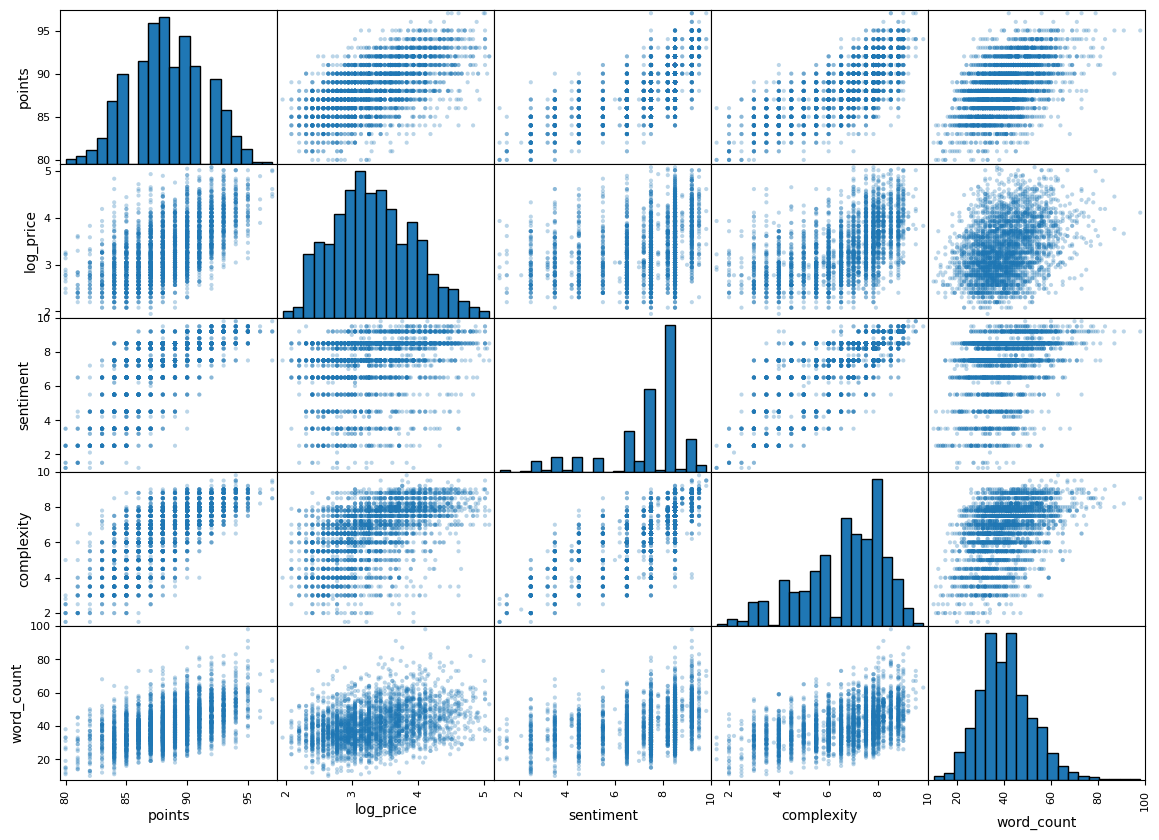

In [133]:
onemli_nitelikler = ["points", "log_price", "sentiment", "complexity", "word_count"]
scatter_matrix(df_wine[onemli_nitelikler],
               figsize=(14, 10),
               alpha=0.3,
               hist_kwds={'bins': 20,'edgecolor': 'black'} )
plt.show()

In [134]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

X_train_raw = strat_train_set.drop(columns=['points'])
y_train = strat_train_set['points'].values

X_test_raw = strat_test_set.drop(columns=['points'])
y_test = strat_test_set['points'].values

cat_cols = ['country_grp', 'variety_grp']
all_num_cols = ['log_price', 'word_count', 'wine_age', 'sentiment', 'body', 'acidity', 'complexity', 'aging']

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy="median"))
])

full_pipeline = ColumnTransformer([
    ("num", num_pipeline, all_num_cols),
    ("cat", OneHotEncoder(drop='first', sparse_output=False), cat_cols)
], verbose_feature_names_out=False)

X_train_arr = full_pipeline.fit_transform(X_train_raw)
X_test_arr = full_pipeline.transform(X_test_raw)
feature_names = full_pipeline.get_feature_names_out()

X_train_df = pd.DataFrame(X_train_arr, columns=feature_names)
X_test_df = pd.DataFrame(X_test_arr, columns=feature_names)

ohe = full_pipeline.named_transformers_['cat']
print(f"\nÜlke Referans Kategorisi : {ohe.categories_[0][0]}")
print(f"Üzüm Referans Kategorisi : {ohe.categories_[1][0]}")


Ülke Referans Kategorisi : Argentina
Üzüm Referans Kategorisi : Bordeaux-style Red Blend


In [135]:
import statsmodels.api as sm

#Baz modele girecek sütunlar
cat_names = [col for col in feature_names if col.startswith('country_grp_') or col.startswith('variety_grp_')]
base_num_cols = ['log_price', 'word_count', 'wine_age']
base_cols = base_num_cols + cat_names

#Baz Model
X_train_base = sm.add_constant(X_train_df[base_cols])
X_test_base = sm.add_constant(X_test_df[base_cols])
ols_base = sm.OLS(y_train, X_train_base).fit()
pred_base = ols_base.predict(X_test_base)

#LLM Destekli Model
X_train_full = sm.add_constant(X_train_df)
X_test_full = sm.add_constant(X_test_df)
ols_full = sm.OLS(y_train, X_train_full).fit()
pred_full = ols_full.predict(X_test_full)

#Katsayı Tablosu
print(ols_full.summary())

f_stat, p_val, df_diff = ols_full.compare_f_test(ols_base)
print(f"\nİç İçe Model F-Testi (LLM Katkısı): F({int(df_diff)}, {int(ols_full.df_resid)}) = {f_stat:.2f}, p-değeri = {p_val:.4e}")

print("\nİstatistiksel Olarak Anlamlı Değişkenler (p < 0.05):")
print(ols_full.pvalues[ols_full.pvalues < 0.05].round(4))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.749
Model:                            OLS   Adj. R-squared:                  0.747
Method:                 Least Squares   F-statistic:                     394.4
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:49:31   Log-Likelihood:                -5878.7
No. Observations:                3200   AIC:                         1.181e+04
Df Residuals:                    3175   BIC:                         1.196e+04
Df Model:                          24                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const       

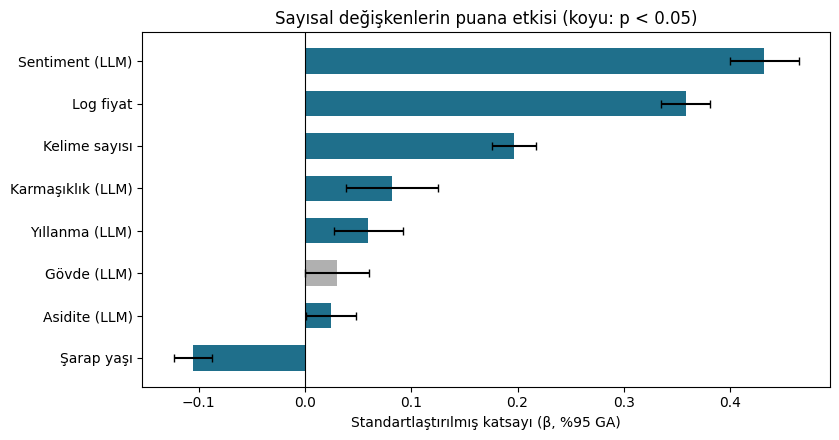

In [136]:
cols = ['sentiment', 'log_price', 'word_count', 'complexity', 'aging', 'body', 'acidity', 'wine_age']
labels = ['Sentiment (LLM)', 'Log fiyat', 'Kelime sayısı', 'Karmaşıklık (LLM)', 'Yıllanma (LLM)', 'Gövde (LLM)', 'Asidite (LLM)', 'Şarap yaşı']

scale = X_train_df[cols].std() / y_train.std()
betas = ols_full.params[cols] * scale

errs = (ols_full.conf_int().loc[cols, 1] - ols_full.conf_int().loc[cols, 0]) / 2 * scale

colors = ['#1f6f8b' if p < 0.05 else '#b0b0b0' for p in ols_full.pvalues[cols]]

plt.figure(figsize=(8.5, 4.5))
plt.barh(labels[::-1], betas[::-1], xerr=errs[::-1], color=colors[::-1], capsize=3, height=0.6)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Standartlaştırılmış katsayı (β, %95 GA)')
plt.title('Sayısal değişkenlerin puana etkisi (koyu: p < 0.05)')
plt.tight_layout()
plt.show()

MODEL KIYASLAMA VE ÇAPRAZ DOĞRULAMA

In [137]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pred_train_base = ols_base.predict(X_train_base)
pred_test_base = ols_base.predict(X_test_base)

pred_train_full = ols_full.predict(X_train_full)
pred_test_full = ols_full.predict(X_test_full)

#Çapraz Doğrulama
base_scores = cross_val_score(LinearRegression(),
                             X_train_df[base_cols],
                             y_train,
                             scoring='neg_mean_squared_error',
                             cv=10)
full_scores = cross_val_score(LinearRegression(),
                            X_train_df, y_train,
                            scoring='neg_mean_squared_error',
                            cv=10)

base_rmse = np.sqrt(-base_scores)
full_rmse = np.sqrt(-full_scores)

tablo_5 = pd.DataFrame({
    'Baz Model': [
        ols_base.rsquared,
        ols_base.rsquared_adj,
        r2_score(y_test, pred_test_base),
        np.sqrt(mean_squared_error(y_test, pred_test_base)),
        mean_absolute_error(y_test, pred_test_base),
        base_rmse.mean(),
        base_rmse.std()
    ],
    'LLM Destekli': [
        ols_full.rsquared,
        ols_full.rsquared_adj,
        r2_score(y_test, pred_test_full),
        np.sqrt(mean_squared_error(y_test, pred_test_full)),
        mean_absolute_error(y_test, pred_test_full),
        full_rmse.mean(),
        full_rmse.std()
    ]
}, index=['Eğitim R²', 'Düzeltilmiş R²', 'Test R²', 'Test RMSE', 'Test MAE', "Cv oratalama RMSE", "Cv Std"])

print("\nBAZ MODEL İLE LLM DESTEKLİ MODELİN KARŞILAŞTIRILMASI")
display(tablo_5)



BAZ MODEL İLE LLM DESTEKLİ MODELİN KARŞILAŞTIRILMASI


,Baz Model,LLM Destekli
Eğitim R²,0.549559,0.748804
Düzeltilmiş R²,0.546867,0.746905
Test R²,0.531259,0.734281
Test RMSE,2.054679,1.546994
Test MAE,1.642318,1.234240
Cv oratalama RMSE,2.045438,1.530219
Cv Std,0.083854,0.057240


TAHMİN GRAFİĞİ

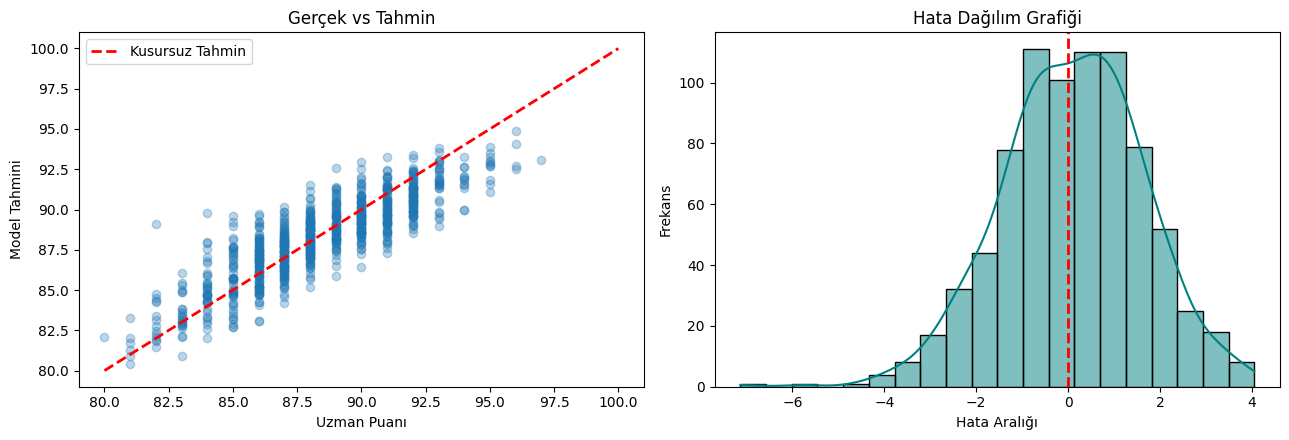

In [138]:
residuals = y_test - pred_test_full

fig,axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].scatter(y_test, pred_test_full, alpha=0.3)
axes[0].plot([80, 100], [80, 100], 'r--', lw=2, label='Kusursuz Tahmin')
axes[0].set_title(f"Gerçek vs Tahmin")
axes[0].set_xlabel("Uzman Puanı")
axes[0].set_ylabel("Model Tahmini")
axes[0].legend()

sns.histplot(residuals, bins=20, kde=True, color='teal', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--', lw=2)
axes[1].set_title("Hata Dağılım Grafiği")
axes[1].set_xlabel("Hata Aralığı")
axes[1].set_ylabel("Frekans")
plt.tight_layout()
plt.show()

In [139]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
_, bp_pval, _, _ = het_breuschpagan(ols_full.resid, ols_full.model.exog)
print("Breusch-Pagan p-değeri:",bp_pval)

#VIF tablosu oluşturma
num_cols_vif = ['log_price', 'word_count', 'wine_age', 'sentiment', 'body', 'acidity', 'complexity', 'aging']

X_vif = sm.add_constant(X_train_df[num_cols_vif])

vif_data = pd.DataFrame()
vif_data["Değişken"] = num_cols_vif
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(num_cols_vif))]

display(vif_data.round(2).sort_values(by="VIF", ascending=False))

Breusch-Pagan p-değeri: 4.108345815553021e-06


,Değişken,VIF
6,complexity,5.79
7,aging,3.22
3,sentiment,2.94
4,body,2.73
5,acidity,1.71
0,log_price,1.51
1,word_count,1.30
2,wine_age,1.05
